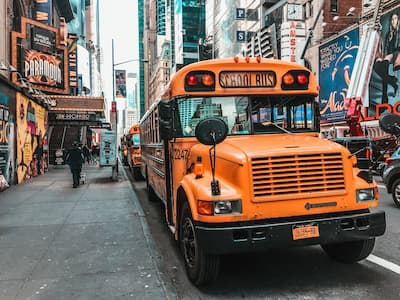

Photo by [Jannis Lucas](https://unsplash.com/@jannis_lucas) on [Unsplash](https://unsplash.com).

# NYC Public School SAT Performance Analysis

This project examines historical, school-level SAT results for New York City public high schools. The file contains three legacy SAT sections—Math, Critical Reading/Reading, and Writing—with each section scored from 200 to 800 points. Their sum therefore ranges from 600 to 2,400.

**Important context:** this is the legacy three-section SAT format, not the current Digital SAT. The College Board now reports two sections—Reading and Writing, and Math—with a total score range of 400–1,600. Do not compare the totals in this project directly with current Digital SAT totals.

The analysis is descriptive. It identifies patterns in the supplied records; it does not measure overall school quality, teaching effectiveness, or individual student ability.

## Dataset source and provenance

The dataset used in this project is **NYC Public School SAT Performance**:

- [Kaggle dataset — Mohamed Mostafa](https://www.kaggle.com/datasets/mohamedmostafa259/nyc-public-school-sat-performance-dataset)
- File used: `schools.csv`
- The Kaggle page's upload/update date is not necessarily the year in which the SAT results were collected. The exact testing year for this particular copy is not established in this repository.
- The dataset is historical and uses the legacy three-section SAT structure. It should not be described as a live or current measure of NYC school performance.
- The repository includes a copy of `schools.csv` so the analysis can be reproduced without manually downloading the file.

For current SAT structure and score reporting, see the [College Board's SAT structure guide](https://satsuite.collegeboard.org/sat-school-day/taking-the-test/structure).

## Problem definition and intended use

**Analytical problem:** understand how the recorded NYC public high schools compare on legacy SAT section averages, how the combined school-level averages vary across boroughs, and whether participation is associated with performance.

The original project questions are preserved:

1. Which schools have an average Math score of at least 640 (80% of the 800-point section maximum)?
2. Which schools have the ten highest combined scores, calculated as the sum of the three school-level section averages?
3. Which borough has the largest standard deviation in combined school-level scores?

The analysis also examines data quality, score distributions, relationships among SAT sections, and the association between participation and scores.

**Intended users:** education analysts, school leaders, researchers, and policy stakeholders looking for descriptive patterns and follow-up questions. The 640 Math threshold is a project-defined screening rule—not an official College Board proficiency benchmark. Rankings should not be used alone for school choice, funding, or judgments about school quality.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Reproducible project setup
from pathlib import Path

# Find the dataset in the current folder or its parent folders.
# This also works when Jupyter is launched from a different project directory.
search_locations = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next(
    (folder / "schools.csv" for folder in search_locations
     if (folder / "schools.csv").is_file()),
    None
)
if DATA_PATH is None:
    raise FileNotFoundError(
        "schools.csv was not found. Keep it in the project folder with this notebook."
    )

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)
print(f"Dataset found: {DATA_PATH.resolve()}")
print(f"Charts will be saved in: {IMAGE_DIR.resolve()}")

Dataset found: /home/runner/work/Analysis-of-SAT-Performance-Across-NYC-Schools/Analysis-of-SAT-Performance-Across-NYC-Schools/schools.csv
Charts will be saved in: /home/runner/work/Analysis-of-SAT-Performance-Across-NYC-Schools/Analysis-of-SAT-Performance-Across-NYC-Schools/images


In [3]:
# Load and understand the raw dataset
score_cols = ["average_math", "average_reading", "average_writing"]
raw_school = pd.read_csv(DATA_PATH)
school = raw_school.copy()

print("Shape:", raw_school.shape)
print("\nColumn names and data types:")
display(raw_school.dtypes.to_frame("data_type"))
print("\nDataset information:")
raw_school.info()
print("\nNumerical summary:")
display(raw_school.describe(include="all").T)
print("\nFirst five rows:")
display(raw_school.head())

# Dataset grain: one row should represent one NYC public high school.
print("\nRows:", len(raw_school))
print("Unique school names:", raw_school["school_name"].nunique())
print("Unique building codes:", raw_school["building_code"].nunique())


Shape: (375, 7)

Column names and data types:


,data_type
school_name,str
borough,str
building_code,str
average_math,int64
average_reading,int64
average_writing,int64
percent_tested,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   school_name      375 non-null    str    
 1   borough          375 non-null    str    
 2   building_code    375 non-null    str    
 3   average_math     375 non-null    int64  
 4   average_reading  375 non-null    int64  
 5   average_writing  375 non-null    int64  
 6   percent_tested   355 non-null    float64
dtypes: float64(1), int64(3), str(3)
memory usage: 20.6 KB

Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school_name,375,375,"New Explorations into Science, Technology and ...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,375,5,Brooklyn,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_code,375,233,X435,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
average_math,375.0,NaN,NaN,NaN,432.944,71.952373,317.0,386.0,415.0,458.5,754.0
average_reading,375.0,NaN,NaN,NaN,424.504,61.881069,302.0,386.0,413.0,445.0,697.0
average_writing,375.0,NaN,NaN,NaN,418.458667,64.548599,284.0,382.0,403.0,437.5,693.0
percent_tested,355.0,NaN,NaN,NaN,64.976338,18.747634,18.5,50.95,64.8,79.6,100.0



First five rows:


,school_name,borough,building_code,average_math,average_reading,average_writing,percent_tested
0,"New Explorations into Science, Technology and ...",Manhattan,M022,657,601,601,NaN
1,Essex Street Academy,Manhattan,M445,395,411,387,78.9
2,Lower Manhattan Arts Academy,Manhattan,M445,418,428,415,65.1
3,High School for Dual Language and Asian Studies,Manhattan,M445,613,453,463,95.9
4,Henry Street School for International Studies,Manhattan,M056,410,406,381,59.7



Rows: 375
Unique school names: 375
Unique building codes: 233


#### Dealing with missing values

In [4]:
# Missing-value audit and justified treatment
missing_audit = pd.DataFrame({
    "missing_count": raw_school.isna().sum(),
    "missing_percent": (raw_school.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_audit)

# percent_tested is not required to calculate SAT section scores or total SAT.
# Preserve its missing values; do not invent participation data through imputation.
print("Missing participation values retained:", school["percent_tested"].isna().sum())

# Review potential duplicate records. Repeated building codes are not automatically
# duplicate schools because several schools may share a building.
print("Completely duplicated rows:", raw_school.duplicated().sum())
print("Repeated school names:", raw_school["school_name"].duplicated().sum())
print("Repeated building codes:", raw_school["building_code"].duplicated().sum())


,missing_count,missing_percent
percent_tested,20,5.33
borough,0,0.00
school_name,0,0.00
building_code,0,0.00
average_math,0,0.00
average_reading,0,0.00
average_writing,0,0.00


Missing participation values retained: 20
Completely duplicated rows: 0
Repeated school names: 0
Repeated building codes: 142


In [5]:
# Raw numeric range checks
score_cols = ["average_math", "average_reading", "average_writing"]
for col in score_cols:
    print(f"{col}: min={school[col].min()}, max={school[col].max()}, "
          f"missing={school[col].isna().sum()}")

print("\nParticipation percentage range:")
print(school["percent_tested"].describe())

# The legacy SAT reports each section on a 200–800 scale.
for col in score_cols:
    assert school[col].dropna().between(200, 800).all(), f"Unexpected {col} score range."

assert school["percent_tested"].dropna().between(0, 100).all(), (
    "Participation percentages must be between 0 and 100."
)

average_math: min=317, max=754, missing=0
average_reading: min=302, max=697, missing=0
average_writing: min=284, max=693, missing=0

Participation percentage range:
count    355.000000
mean      64.976338
std       18.747634
min       18.500000
25%       50.950000
50%       64.800000
75%       79.600000
max      100.000000
Name: percent_tested, dtype: float64


### Cleaning decisions before the main analysis

- **Missing `percent_tested`:** retain the 20 missing values. Do not replace them with zero or an average; missing means unreported/unknown, not zero participation.
- **SAT scores:** all three section columns are present for the schools in this file. Keep the original score values after confirming the legacy 200–800 range.
- **Text fields:** trim leading/trailing whitespace, but do not rewrite school names or merge schools based only on a shared building code.
- **Duplicates:** investigate exact duplicate rows and school-name duplicates separately. A repeated `building_code` is not a duplicate-school rule.
- **Rows:** do not drop any schools for the analyses of SAT performance. Participation analysis will use complete pairs only and will report its sample size.

### Cleaning and post-cleaning validation

The next cell standardizes text, checks numeric conversion, validates types and permitted values, and confirms that no school rows were lost.


In [6]:
# Schema, cleaning, types, and categorical consistency checks
from pandas.api.types import is_numeric_dtype, is_string_dtype

expected_columns = {
    "school_name", "borough", "building_code",
    "average_math", "average_reading", "average_writing", "percent_tested"
}
missing_columns = expected_columns - set(raw_school.columns)
unexpected_columns = set(raw_school.columns) - expected_columns
print("Missing expected columns:", missing_columns)
print("Unexpected columns:", unexpected_columns)
assert not missing_columns, "Required dataset columns are missing."

# Standardize surrounding whitespace only; retain original category meaning.
for col in ["school_name", "borough", "building_code"]:
    school[col] = school[col].astype("string").str.strip()

# Track missingness before numeric conversion so malformed strings cannot silently
# become unreviewed NaN values.
numeric_cols = score_cols + ["percent_tested"]
missing_before_conversion = school[numeric_cols].isna().sum()
for col in numeric_cols:
    school[col] = pd.to_numeric(school[col], errors="coerce")
missing_after_conversion = school[numeric_cols].isna().sum()
new_missing = missing_after_conversion - missing_before_conversion
print("New missing values created by numeric conversion:")
display(new_missing.to_frame("new_missing"))
assert (new_missing == 0).all(), "Numeric conversion introduced new missing values."

expected_boroughs = {"Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"}
observed_boroughs = set(school["borough"].dropna().unique())
print("Observed boroughs:", observed_boroughs)
print("Unexpected borough labels:", observed_boroughs - expected_boroughs)
print("Missing borough values:", school["borough"].isna().sum())
assert observed_boroughs == expected_boroughs
assert school["borough"].notna().all()
assert school["school_name"].notna().all()
assert school["school_name"].is_unique, "School names should be unique in this file."
assert school[["school_name", "borough", "building_code"]].apply(
    lambda col: col.eq(col.str.strip()).all()
).all(), "Text columns still contain surrounding whitespace."

# Expected storage types after conversion.
assert all(is_string_dtype(school[col].dtype)
           for col in ["school_name", "borough", "building_code"])
assert all(is_numeric_dtype(school[col].dtype) for col in numeric_cols)

# Legacy SAT section scores are 200–800; participation is 0–100%.
for col in score_cols:
    invalid = school[col].notna() & ~school[col].between(200, 800)
    print(f"{col}: invalid values = {invalid.sum()}")
    assert not invalid.any()
    assert np.isclose(school[col].dropna() % 1, 0).all(), (
        f"{col} should contain whole-number scaled scores."
    )

invalid_participation = (
    school["percent_tested"].notna()
    & ~school["percent_tested"].between(0, 100)
)
print("Invalid participation percentages:", invalid_participation.sum())
assert not invalid_participation.any()

print("Rows before cleaning:", len(raw_school))
print("Rows after cleaning:", len(school))
assert len(school) == len(raw_school), "Cleaning unexpectedly changed the row count."
assert school.columns.tolist() == raw_school.columns.tolist(), (
    "Cleaning changed the source schema before feature engineering."
)

print("Missing values after cleaning:")
display(school.isna().sum())

print("Exact duplicate rows:", school.duplicated().sum())
print("Duplicate school names:", school["school_name"].duplicated().sum())
print("Repeated building codes (not necessarily errors):",
      school["building_code"].duplicated().sum())
print("Unique building codes:", school["building_code"].nunique())
assert school.duplicated().sum() == 0


Missing expected columns: set()
Unexpected columns: set()
New missing values created by numeric conversion:


,new_missing
average_math,0
average_reading,0
average_writing,0
percent_tested,0


Observed boroughs: {'Manhattan', 'Staten Island', 'Queens', 'Brooklyn', 'Bronx'}
Unexpected borough labels: set()
Missing borough values: 0
average_math: invalid values = 0
average_reading: invalid values = 0
average_writing: invalid values = 0
Invalid participation percentages: 0
Rows before cleaning: 375
Rows after cleaning: 375
Missing values after cleaning:


school_name         0
borough             0
building_code       0
average_math        0
average_reading     0
average_writing     0
percent_tested     20
dtype: int64

Exact duplicate rows: 0
Duplicate school names: 0
Repeated building codes (not necessarily errors): 142
Unique building codes: 233


## Which NYC schools have the best math results?

In [7]:
# Identify schools meeting the project's original math benchmark.
# 640 represents 80% of the maximum possible section score (800).
best_maths_score = (
    school.loc[school["average_math"] >= 640, ["school_name", "borough", "average_math"]]
    .sort_values("average_math", ascending=False)
)
display(best_maths_score)

# A horizontal chart is easier to read when school names are long.
plt.figure(figsize=(11, max(5, len(best_maths_score) * 0.35)))
sns.barplot(data=best_maths_score, y="school_name", x="average_math", color="steelblue")
plt.title("NYC Schools with Average Math Scores of at Least 640")
plt.xlabel("Average Math SAT score")
plt.ylabel("School")
plt.xlim(640, 800)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "01_math_benchmark_schools.png", dpi=180, bbox_inches="tight")
plt.show()

,school_name,borough,average_math
88,Stuyvesant High School,Manhattan,754
170,Bronx High School of Science,Bronx,714
93,Staten Island Technical High School,Staten Island,711
365,Queens High School for the Sciences at York Co...,Queens,701
68,"High School for Mathematics, Science, and Engi...",Manhattan,683
280,Brooklyn Technical High School,Brooklyn,682
333,Townsend Harris High School,Queens,680
174,High School of American Studies at Lehman College,Bronx,669
0,"New Explorations into Science, Technology and ...",Manhattan,657
45,Eleanor Roosevelt High School,Manhattan,641


## What are the top 10 performing schools based on the combined SAT scores?

In [8]:
# Engineer total SAT only when all three section averages are present.
# This is the sum of school-level section averages, not an individual student's
# score and not a student-weighted borough average.
school["total_SAT"] = school[score_cols].sum(axis=1, min_count=3)

# Validate the engineered feature against the legacy possible score range.
assert school["total_SAT"].dropna().between(600, 2400).all()
complete_sections = school[score_cols].notna().all(axis=1)
assert school["total_SAT"].notna().equals(complete_sections)
assert np.allclose(
    school.loc[complete_sections, "total_SAT"],
    school.loc[complete_sections, score_cols].sum(axis=1)
)

schools = (
    school.loc[school["total_SAT"].notna(),
               ["school_name", "borough", "average_math", "average_reading",
                "average_writing", "total_SAT"]]
    .sort_values(["total_SAT", "school_name"],
                 ascending=[False, True], kind="mergesort")
)
top_10_schools = schools.head(10)
display(top_10_schools)

plt.figure(figsize=(11, 6))
sns.barplot(data=top_10_schools, y="school_name", x="total_SAT", color="slateblue")
plt.title("Top 10 NYC Schools by Combined Legacy SAT Score")
plt.xlabel("Sum of school-level section averages (600–2,400)")
plt.ylabel("School")
plt.xlim(600, 2400)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "02_top_10_combined_sat.png", dpi=180, bbox_inches="tight")
plt.show()

,school_name,borough,average_math,average_reading,average_writing,total_SAT
88,Stuyvesant High School,Manhattan,754,697,693,2144
170,Bronx High School of Science,Bronx,714,660,667,2041
93,Staten Island Technical High School,Staten Island,711,660,670,2041
174,High School of American Studies at Lehman College,Bronx,669,672,672,2013
333,Townsend Harris High School,Queens,680,640,661,1981
365,Queens High School for the Sciences at York Co...,Queens,701,621,625,1947
5,Bard High School Early College,Manhattan,634,641,639,1914
280,Brooklyn Technical High School,Brooklyn,682,608,606,1896
45,Eleanor Roosevelt High School,Manhattan,641,617,631,1889
68,"High School for Mathematics, Science, and Engi...",Manhattan,683,610,596,1889


## Which single borough has the largest standard deviation in the combined SAT score?

In [9]:
# Borough-level performance and dispersion
# pandas std() uses ddof=1: this is the sample standard deviation.
borough_stats = (
    school.groupby("borough")["total_SAT"]
    .agg(num_schools="count", mean_SAT="mean", median_SAT="median",
         std_SAT="std", min_SAT="min", max_SAT="max")
    .reset_index()
)
borough_stats[["mean_SAT", "median_SAT", "std_SAT"]] = borough_stats[
    ["mean_SAT", "median_SAT", "std_SAT"]
].round(2)
display(borough_stats.sort_values("mean_SAT", ascending=False))

largest_std_dev = (
    borough_stats.nlargest(1, "std_SAT")
    [["borough", "num_schools", "mean_SAT", "median_SAT", "std_SAT"]]
    .reset_index(drop=True)
)
print("Borough with the largest sample standard deviation:")
display(largest_std_dev)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=borough_stats, x="borough", y="mean_SAT", ax=axes[0], color="steelblue")
axes[0].set_title("Mean Combined SAT by Borough")
axes[0].set_ylabel("Mean sum of section averages (600–2,400)")
axes[0].tick_params(axis="x", rotation=35)
sns.barplot(data=borough_stats, x="borough", y="std_SAT", ax=axes[1], color="darkorange")
axes[1].set_title("Variation in Combined SAT by Borough")
axes[1].set_ylabel("Sample standard deviation (points)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
fig.savefig(IMAGE_DIR / "03_borough_mean_and_variation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

,borough,num_schools,mean_SAT,median_SAT,std_SAT,min_SAT,max_SAT
4,Staten Island,10,1439.00,1382.0,222.30,1258,2041
3,Queens,69,1345.48,1290.0,195.25,978,1981
2,Manhattan,89,1340.13,1284.0,230.29,1005,2144
1,Brooklyn,109,1230.26,1186.0,154.87,926,1896
0,Bronx,98,1202.72,1190.0,150.39,924,2041


Borough with the largest sample standard deviation:


,borough,num_schools,mean_SAT,median_SAT,std_SAT
0,Manhattan,89,1340.13,1284.0,230.29


## Exploratory analysis: group sizes, distributions, and relationships

The following sections compare borough samples, investigate score distributions and outliers, and examine associations. All results remain descriptive.


### Group-size and distribution checks

In [10]:
# Group size matters when comparing borough averages and standard deviations.
borough_sizes = school.groupby("borough").size().rename("school_count").sort_values(ascending=False)
display(borough_sizes.to_frame())
print("Total schools across boroughs:", borough_sizes.sum())
print("Schools with complete SAT sections:", school["total_SAT"].notna().sum())
print("Schools missing at least one SAT section:", school["total_SAT"].isna().sum())

# Compare mean and median: a large gap can indicate skew or influential values.
distribution_summary = school.groupby("borough")["total_SAT"].agg(
    count="count", mean="mean", median="median", std="std",
    minimum="min", maximum="max"
)
distribution_summary["mean_minus_median"] = distribution_summary["mean"] - distribution_summary["median"]
display(distribution_summary.round(2))

,school_count
borough,
Brooklyn,109
Bronx,98
Manhattan,89
Queens,69
Staten Island,10


Total schools across boroughs: 375
Schools with complete SAT sections: 375
Schools missing at least one SAT section: 0


,count,mean,median,std,minimum,maximum,mean_minus_median
borough,,,,,,,
Bronx,98,1202.72,1190.0,150.39,924,2041,12.72
Brooklyn,109,1230.26,1186.0,154.87,926,1896,44.26
Manhattan,89,1340.13,1284.0,230.29,1005,2144,56.13
Queens,69,1345.48,1290.0,195.25,978,1981,55.48
Staten Island,10,1439.00,1382.0,222.30,1258,2041,57.00


### Outlier investigation (IQR method)

The numerical outlier count uses one **global IQR fence across all schools**. The borough boxplot calculates its whiskers and visual outlier markers separately within each borough, so the number of points shown in that chart does not have to equal the global outlier count.

IQR flags unusually low or high observations for investigation; it is not an automatic rule for deleting schools.

In [11]:
# IQR flags unusually low/high observations for investigation, not automatic deletion.
q1 = school["total_SAT"].quantile(0.25)
q3 = school["total_SAT"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
below_fence = school["total_SAT"] < lower_fence
above_fence = school["total_SAT"] > upper_fence
sat_outliers = school.loc[
    below_fence | above_fence,
    ["school_name", "borough", "total_SAT"]
].copy()
sat_outliers["outlier_direction"] = np.where(
    sat_outliers["total_SAT"] > upper_fence, "High", "Low"
)
sat_outliers = sat_outliers.sort_values("total_SAT")
print(f"IQR lower fence: {lower_fence:.1f}; upper fence: {upper_fence:.1f}")
print("Potential statistical outliers:", len(sat_outliers))
print("Below lower fence:", int(below_fence.sum()))
print("Above upper fence:", int(above_fence.sum()))
display(sat_outliers)

borough_order = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
plt.figure(figsize=(10, 5))
sns.boxplot(data=school, x="borough", y="total_SAT", order=borough_order)
plt.title("Combined SAT Score Distribution and Potential Outliers by Borough")
plt.xlabel("Borough")
plt.ylabel("Sum of school-level section averages")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "04_sat_distribution_by_borough.png", dpi=180, bbox_inches="tight")
plt.show()

IQR lower fence: 896.8; upper fence: 1590.8
Potential statistical outliers: 27
Below lower fence: 0
Above upper fence: 27


,school_name,borough,total_SAT,outlier_direction
14,Institute for Collaborative Education,Manhattan,1592,High
31,NYC Museum School,Manhattan,1612,High
212,Frank Sinatra School of the Arts High School,Queens,1622,High
308,Leon M. Goldstein High School for the Sciences,Brooklyn,1640,High
275,Millennium Brooklyn High School,Brooklyn,1643,High
51,Manhattan / Hunter Science High School,Manhattan,1647,High
23,Baruch College Campus High School,Manhattan,1649,High
58,Columbia Secondary School,Manhattan,1690,High
26,NYC Lab School for Collaborative Studies,Manhattan,1700,High
18,Millennium High School,Manhattan,1704,High


### Relationships between SAT sections and participation

In [12]:
# SAT-section relationships: Pearson captures linear association; Spearman captures
# monotonic rank association. All three section columns are complete in this file.
section_corr_pearson = school[score_cols].corr(method="pearson")
section_corr_spearman = school[score_cols].corr(method="spearman")
display(section_corr_pearson.round(3))
display(section_corr_spearman.round(3))

section_names = {
    "average_math": "Math",
    "average_reading": "Critical Reading",
    "average_writing": "Writing"
}
pearson_plot = section_corr_pearson.rename(index=section_names, columns=section_names)
spearman_plot = section_corr_spearman.rename(index=section_names, columns=section_names)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(pearson_plot, annot=True, vmin=-1, vmax=1, cmap="coolwarm",
            square=True, ax=axes[0])
axes[0].set_title("SAT Section Correlations (Pearson)")
sns.heatmap(spearman_plot, annot=True, vmin=-1, vmax=1, cmap="coolwarm",
            square=True, ax=axes[1])
axes[1].set_title("SAT Section Correlations (Spearman)")
plt.tight_layout()
fig.savefig(IMAGE_DIR / "05_sat_section_correlations.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Participation is missing for some schools. Use complete pairs only and state n.
participation_data = school[["percent_tested", "total_SAT"]].dropna()
print("Schools included in participation analysis:", len(participation_data))
print("Schools excluded due to missing participation or total SAT:",
      len(school) - len(participation_data))
pearson_participation = participation_data["percent_tested"].corr(
    participation_data["total_SAT"], method="pearson")
spearman_participation = participation_data["percent_tested"].corr(
    participation_data["total_SAT"], method="spearman")
print("Participation vs total SAT — Pearson:", round(pearson_participation, 3))
print("Participation vs total SAT — Spearman:", round(spearman_participation, 3))

# Create a NEW figure explicitly. This prevents the previous heatmap from being
# saved a second time under the participation-chart filename.
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(
    data=participation_data, x="percent_tested", y="total_SAT", ax=ax,
    scatter_kws={"alpha": 0.6, "s": 35},
    line_kws={"color": "red"}
)
ax.set_title("Participation and School-Level SAT Performance")
ax.set_xlabel("Students tested (%)")
ax.set_ylabel("Sum of school-level section averages (600–2,400)")
ax.text(
    0.03, 0.97,
    f"n = {len(participation_data)}\nPearson r = {pearson_participation:.3f}\n"
    f"Spearman ρ = {spearman_participation:.3f}",
    transform=ax.transAxes, va="top",
    bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "alpha": 0.85}
)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "06_participation_vs_sat.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

,average_math,average_reading,average_writing
average_math,1.000,0.928,0.934
average_reading,0.928,1.000,0.985
average_writing,0.934,0.985,1.000


,average_math,average_reading,average_writing
average_math,1.000,0.875,0.884
average_reading,0.875,1.000,0.965
average_writing,0.884,0.965,1.000


Schools included in participation analysis: 355
Schools excluded due to missing participation or total SAT: 20
Participation vs total SAT — Pearson: 0.604
Participation vs total SAT — Spearman: 0.606


### Post-analysis validation and stakeholder interpretation

In [13]:
# Post-analysis validation: rankings, group summaries, and calculations reconcile.
assert schools["total_SAT"].is_monotonic_decreasing
assert len(top_10_schools) == min(10, len(schools))
assert np.allclose(
    school.loc[complete_sections, "total_SAT"],
    school.loc[complete_sections, score_cols].sum(axis=1)
)
assert borough_stats["num_schools"].sum() == len(school)
assert borough_stats["num_schools"].sum() == school["borough"].notna().sum()
assert school["total_SAT"].between(600, 2400).all()
assert section_corr_pearson.shape == (3, 3)
assert np.allclose(section_corr_pearson, section_corr_pearson.T)
assert participation_data["percent_tested"].between(0, 100).all()
assert len(participation_data) == school["percent_tested"].notna().sum()
assert -1 <= pearson_participation <= 1
assert -1 <= spearman_participation <= 1

# Confirm the two relationship charts are separate, non-empty image files.
assert (IMAGE_DIR / "05_sat_section_correlations.png").stat().st_size > 10_000
assert (IMAGE_DIR / "06_participation_vs_sat.png").stat().st_size > 10_000

print("Post-analysis validation passed.")
print("Top school:", top_10_schools.iloc[0]["school_name"],
      "| combined SAT:", top_10_schools.iloc[0]["total_SAT"])
print("Borough with highest mean SAT:",
      borough_stats.loc[borough_stats["mean_SAT"].idxmax(), "borough"])
print("Borough with highest sample standard deviation:",
      borough_stats.loc[borough_stats["std_SAT"].idxmax(), "borough"])

# Interpretation guardrails:
# - Mean is the arithmetic average; median is the middle observation.
# - Standard deviation measures spread, not achievement.
# - A smaller group may produce a less stable descriptive estimate.
# - Correlation is association, not proof of cause and effect.
# - School-level averages cannot be used to infer individual student outcomes.

Post-analysis validation passed.
Top school: Stuyvesant High School | combined SAT: 2144
Borough with highest mean SAT: Staten Island
Borough with highest sample standard deviation: Manhattan


## Results and stakeholder interpretation

The results below are calculated from the current file by the next cell. Interpret them with these distinctions:

- The **mean** is the arithmetic average across recorded schools in a borough; each school receives equal weight because student counts are not included.
- The **median** is the middle school's score. When the mean is above the median, relatively high-scoring schools may be pulling the mean upward.
- The **standard deviation** describes how spread out school scores are within a borough. The notebook uses pandas' sample standard deviation (`ddof=1`); a larger value means greater variation, not a higher average.
- The 640 Math cutoff is a user-defined threshold (80% of 800), not an official proficiency standard.
- Pearson and Spearman coefficients describe association. Neither shows that participation causes higher scores or that one SAT section causes another.
- Participation analysis excludes schools with missing participation percentages; this subset may differ systematically from schools with reported values.

In [14]:
# Dynamic summary for stakeholders and interview discussion
highest_mean_row = borough_stats.loc[borough_stats["mean_SAT"].idxmax()]
highest_median_row = borough_stats.loc[borough_stats["median_SAT"].idxmax()]
highest_std_row = borough_stats.loc[borough_stats["std_SAT"].idxmax()]
top_school = top_10_schools.iloc[0]
math_threshold_count = int((school["average_math"] >= 640).sum())

print(f"Dataset: {len(school):,} schools across {school['borough'].nunique()} boroughs.")
print(f"Math threshold: {math_threshold_count} schools scored at least 640/800.")
print(
    f"Highest combined school-level section-average sum: {top_school['school_name']} "
    f"({int(top_school['total_SAT']):,}/2,400)."
)
print(
    f"Highest borough mean: {highest_mean_row['borough']} "
    f"({highest_mean_row['mean_SAT']:.2f}; n={int(highest_mean_row['num_schools'])})."
)
print(
    f"Highest borough median: {highest_median_row['borough']} "
    f"({highest_median_row['median_SAT']:.2f}; n={int(highest_median_row['num_schools'])})."
)
print(
    f"Greatest within-borough sample spread: {highest_std_row['borough']} "
    f"(SD={highest_std_row['std_SAT']:.2f}; n={int(highest_std_row['num_schools'])})."
)
print(
    f"IQR outliers: {len(sat_outliers)} total "
    f"({int(below_fence.sum())} below and {int(above_fence.sum())} above the global fences)."
)
print(
    "SAT-section Pearson correlations: "
    f"Math–Reading={section_corr_pearson.loc['average_math','average_reading']:.3f}; "
    f"Math–Writing={section_corr_pearson.loc['average_math','average_writing']:.3f}; "
    f"Reading–Writing={section_corr_pearson.loc['average_reading','average_writing']:.3f}."
)
print(
    f"Participation relationship (n={len(participation_data)}): "
    f"Pearson r={pearson_participation:.3f}; "
    f"Spearman rho={spearman_participation:.3f}."
)
print(
    "Interpretation: these are descriptive school-level associations. "
    "The data do not identify why scores differ or establish causal effects."
)

Dataset: 375 schools across 5 boroughs.
Math threshold: 10 schools scored at least 640/800.
Highest combined school-level section-average sum: Stuyvesant High School (2,144/2,400).
Highest borough mean: Staten Island (1439.00; n=10).
Highest borough median: Staten Island (1382.00; n=10).
Greatest within-borough sample spread: Manhattan (SD=230.29; n=89).
IQR outliers: 27 total (0 below and 27 above the global fences).
SAT-section Pearson correlations: Math–Reading=0.928; Math–Writing=0.934; Reading–Writing=0.985.
Participation relationship (n=355): Pearson r=0.604; Spearman rho=0.606.
Interpretation: these are descriptive school-level associations. The data do not identify why scores differ or establish causal effects.


## Limitations and recommendations for stakeholders

- **Historical measurement:** the file uses the legacy three-section SAT scale (600–2,400). The exact test year for this Kaggle copy is not established here. It must not be presented as current Digital SAT performance.
- **Coverage:** the analysis describes the 375 school records in this file; it does not prove that every NYC public high school is represented.
- **Unit of analysis:** each row represents a school, not an individual student. School-level averages cannot be used to infer individual student outcomes.
- **Unweighted borough means:** student counts/test-taker counts are not included, so each school contributes equally to borough means. These are not student-weighted borough averages.
- **Participation missingness:** missing `percent_tested` values are retained. Participation correlations use complete pairs only; missingness may not be random.
- **Comparability:** boroughs contain different numbers of schools. Interpret means and standard deviations alongside group sizes; Staten Island has a much smaller group than the other boroughs.
- **Outliers:** IQR flags are investigation prompts. Extreme but valid school averages should not be removed simply to make distributions look smoother.
- **Causality and confounding:** relationships among SAT sections and between participation and scores do not establish causal effects. School context, student composition, resources, selection effects, and other unmeasured factors may influence both.
- **Measurement:** SAT averages alone are not a complete measure of school quality, teaching effectiveness, or student potential.

**Stakeholder conclusion:** use these results to identify patterns and formulate follow-up questions—not to rank school quality conclusively or allocate resources using SAT scores alone. A stronger equity analysis would combine current, comparable school-year SAT data with enrollment, test-taker counts, socioeconomic indicators, school resources, and longitudinal outcomes. Any future comparison should also align the SAT score format and testing year.